# Cleaning the Spotify Churn dataset - Overview and goals

This notebook performs a structured data cleaning and exploratory analysis on a Spotify churn dataset with the goal of understanding what differentiates users who churn from those who remain. In this notebook we will:
- Load the dataset and inspect its structure (rows, columns, data types).
- Identify missing values, duplicates, and basic statistics.
- Visualize distributions, categorical breakdowns, outliers, and relationships with the target.
- Run simple statistical tests (chi-square for categorical features; t-test for numeric features) to check for significance.
- Build a baseline Random Forest model to get feature importances and evaluate predictive performance.

Expectations and success criteria:
- A clear, reproducible data-cleaning and EDA pipeline.
- Visualizations that clarify which features might be predictive of churn.
- A baseline model with a short interpretation of the most important predictors.

# Libraries and tools

This cell imports standard Python libraries used throughout the notebook:
- `pandas` and `numpy` for data handling and numeric operations.
- `matplotlib` and `seaborn` for plotting and visual exploration.
- `scipy.stats` for hypothesis tests (t-test, chi-square).
- `scikit-learn` utilities for preprocessing, splitting data, and building a baseline Random Forest model.

Keep this cell unchanged unless you add new analysis or modeling steps that require other libraries.

In [12]:
#Data Handling
import os
import numpy as np # linear algebra
import pandas as pd # data processing
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind
from scipy.stats import chi2_contingency


from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

### 1) Load the dataset

We read the CSV into a pandas DataFrame named `df`. After loading we display a small sample so you can inspect the columns and value formats. Replace the filename if your CSV is stored in a different path.

Expected outputs:
- `df.head(2)` — first two rows to preview column names and values.

In [13]:
import pandas as pd
df = pd.read_csv("spotify_churn_dataset.csv")

#show sample of data
df.head(2)

,user_id,gender,age,country,subscription_type,listening_time,songs_played_per_day,skip_rate,device_type,ads_listened_per_week,offline_listening,is_churned
0,1,Female,54,CA,Free,26,23,0.20,Desktop,31,0,1
1,2,Other,33,DE,Family,141,62,0.34,Web,0,1,0


# Dataframe summary: structure and data types

Use `df.info()` to get:
- Number of rows and columns.
- Columns, non-null counts, and data types.

This helps detect missing data and whether categorical columns are stored as object types.

In [14]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   user_id                8000 non-null   int64  
 1   gender                 8000 non-null   object 
 2   age                    8000 non-null   int64  
 3   country                8000 non-null   object 
 4   subscription_type      8000 non-null   object 
 5   listening_time         8000 non-null   int64  
 6   songs_played_per_day   8000 non-null   int64  
 7   skip_rate              8000 non-null   float64
 8   device_type            8000 non-null   object 
 9   ads_listened_per_week  8000 non-null   int64  
 10  offline_listening      8000 non-null   int64  
 11  is_churned             8000 non-null   int64  
dtypes: float64(1), int64(7), object(4)
memory usage: 750.1+ KB


,user_id,age,listening_time,songs_played_per_day,skip_rate,ads_listened_per_week,offline_listening,is_churned
count,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,4000.50000,37.662125,154.068250,50.127250,0.300127,6.943875,0.747750,0.258875
std,2309.54541,12.740359,84.015596,28.449762,0.173594,13.617953,0.434331,0.438044
min,1.00000,16.000000,10.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,2000.75000,26.000000,81.000000,25.000000,0.150000,0.000000,0.000000,0.000000
50%,4000.50000,38.000000,154.000000,50.000000,0.300000,0.000000,1.000000,0.000000
75%,6000.25000,49.000000,227.000000,75.000000,0.450000,5.000000,1.000000,1.000000
max,8000.00000,59.000000,299.000000,99.000000,0.600000,49.000000,1.000000,1.000000


# Missing values, duplicates, and dataset dimensions

This cell prints:
- A per-column count of missing values to identify where data cleaning is needed.
- The number of duplicate rows, which we may drop if they’re exact duplicates.
- The dataset shape (rows, columns).

In [15]:
#show missing value in data
print(f"Missing Value = {df.isnull().sum()}")

#show duplicated value
print(f'Duplicated = {df.duplicated().sum()}')

#the shape of data
print (f'Shape = {df.shape}')

Missing Value = user_id                  0
gender                   0
age                      0
country                  0
subscription_type        0
listening_time           0
songs_played_per_day     0
skip_rate                0
device_type              0
ads_listened_per_week    0
offline_listening        0
is_churned               0
dtype: int64
Duplicated = 0
Shape = (8000, 12)


# Visualising the missing values - percentage bar plot & heatmap

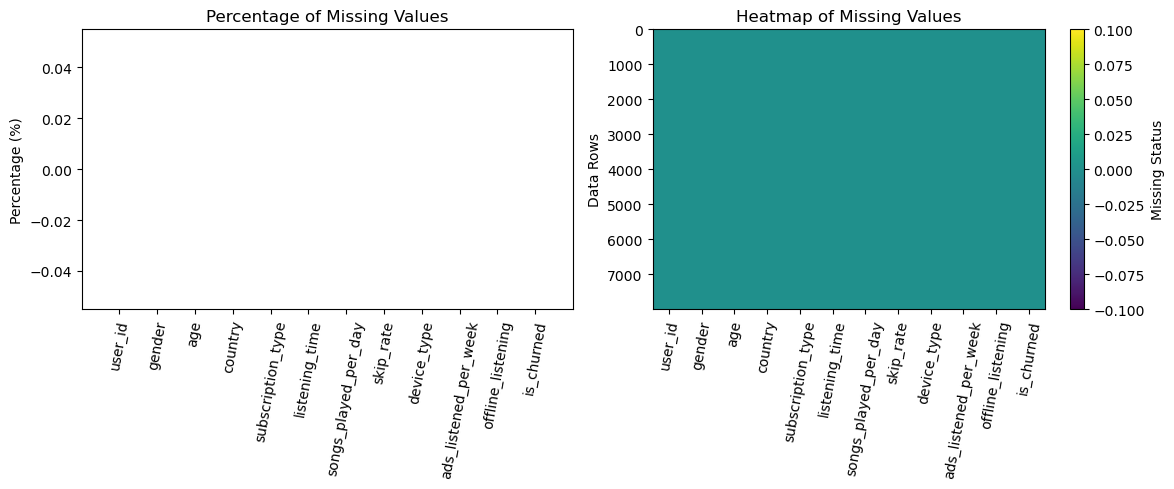

In [16]:
missing = df.isnull().sum()
percentage_missing = (missing / df.shape[0]) * 100

# Create figure and subplots
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# 1. Bar plot for missing values percentage
ax[0].bar(percentage_missing.index, percentage_missing, color='skyblue')
ax[0].set_title("Percentage of Missing Values")
ax[0].set_ylabel("Percentage (%)")
ax[0].tick_params(axis='x', rotation=80)

# 2. Heatmap of missing values
im = ax[1].imshow(df.isnull(), aspect='auto', cmap='viridis', interpolation='nearest')
fig.colorbar(im, ax=ax[1], label='Missing Status')
ax[1].set_title("Heatmap of Missing Values")
ax[1].set_ylabel("Data Rows")
ax[1].set_xticks(range(len(df.columns)))
ax[1].set_xticklabels(df.columns, rotation=80)

# Adjust layout and show
fig.tight_layout()
plt.show()

# Column names

List all column names so we can plan which columns to treat as numeric, categorical, or identifiers to drop during modeling.

In [17]:
#show all columns name
df.columns

Index(['user_id', 'gender', 'age', 'country', 'subscription_type',
       'listening_time', 'songs_played_per_day', 'skip_rate', 'device_type',
       'ads_listened_per_week', 'offline_listening', 'is_churned'],
      dtype='object')

# Categorical Columns :-
### gender
### country
### subscription_type
### device_type


# Checking the values of the categorical data for inconsistencies

In [18]:
gender_categories = df['gender'].unique()
print('gender:', gender_categories)

country_categories = df['country'].unique()
print('country:', country_categories)

subscription_type_categories = df['subscription_type'].unique()
print('subscription_type:', subscription_type_categories)

gender: ['Female' 'Other' 'Male']
country: ['CA' 'DE' 'AU' 'US' 'UK' 'IN' 'FR' 'PK']
subscription_type: ['Free' 'Family' 'Premium' 'Student']


#### Hence, there are no inconsistencies in categorical data.

# Summary statistics for numeric features

`df.describe().T` returns summary statistics (count, mean, std, min, quartiles, max) for numeric columns. Use this to detect outliers or implausible values (e.g., negative ages).

In [19]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
user_id,8000.0,4000.500000,2309.545410,1.0,2000.75,4000.5,6000.25,8000.0
age,8000.0,37.662125,12.740359,16.0,26.00,38.0,49.00,59.0
listening_time,8000.0,154.068250,84.015596,10.0,81.00,154.0,227.00,299.0
songs_played_per_day,8000.0,50.127250,28.449762,1.0,25.00,50.0,75.00,99.0
skip_rate,8000.0,0.300127,0.173594,0.0,0.15,0.3,0.45,0.6
ads_listened_per_week,8000.0,6.943875,13.617953,0.0,0.00,0.0,5.00,49.0
offline_listening,8000.0,0.747750,0.434331,0.0,0.00,1.0,1.00,1.0
is_churned,8000.0,0.258875,0.438044,0.0,0.00,0.0,1.00,1.0


## Data Analysis - visual overview

We now begin exploratory visual analysis. Visualizations below include distributions by gender, age histograms, and other visual checks to build intuition about the dataset and potential predictors of churn.

#### BOX PLOT - provides a quick, high-level summary of key statistics like the median, quartiles, and outliers
#### HISTOGRAM - shows where the data is most concentrated and how spread out the values are
#### both together can be used to identify skewedness and outliers 

# Gender vs Age - barplot

This plot shows average age by gender. Use it to check demographic distributions and whether a specific gender group skews older/younger — useful for later analysis and potential stratification.

<Axes: xlabel='gender', ylabel='age'>

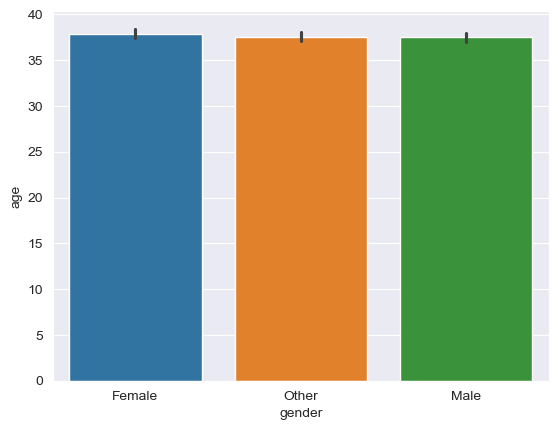

In [20]:
sns.set_style('darkgrid')
sns.barplot(x='gender', y='age', hue='gender', data=df)

# Age distribution with KDE

A histogram with kernel density estimate to visualize the full age distribution. Pay attention to multimodality, mass at extreme ages, or odd bins that suggest data entry errors.

A second version of age histogram (different styling) to reinforce the distributional insight. Consistency across plots increases confidence in observed patterns.

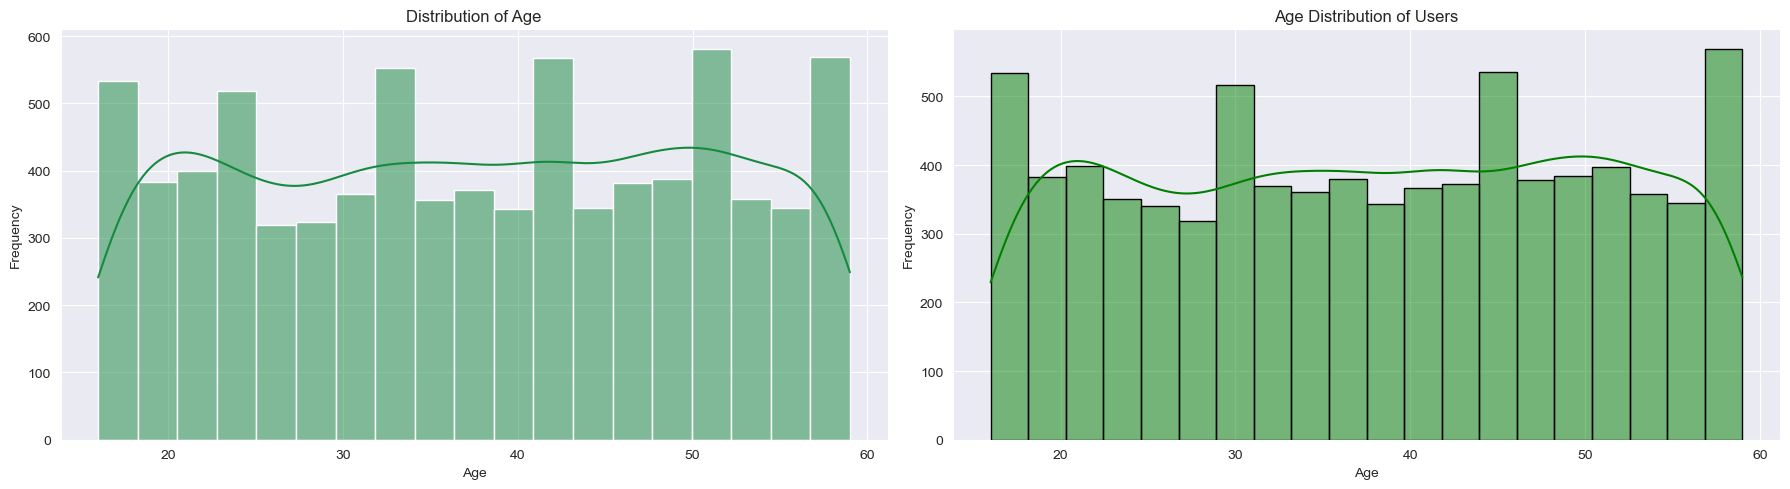

In [21]:
df = pd.read_csv('spotify_churn_dataset.csv')

# Calculate gender counts (assuming df and libraries are already imported)
gender_counts = df['gender'].value_counts()

# Set up matplotlib subplots
fig, axes = plt.subplots(1, 2, figsize=(18, 5))  # 1 row, 3 columns

# Plot 2: Age Distribution with KDE
sns.histplot(df['age'].dropna(), kde=True, color='#158A40', ax=axes[0])
axes[0].set_title('Distribution of Age')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Frequency')

# Plot 3: Age Histogram (specific settings)
sns.histplot(df['age'], bins=20, kde=True, color='green', edgecolor='black', ax=axes[1])
axes[1].set_title("Age Distribution of Users")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### Numerical analysis — identifying numeric features

We detect numeric columns (integers and floats) and list them. These columns will be used for numeric visualizations, outlier detection, and statistical testing.

In [22]:
numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns
print(numerical_cols)

Index(['user_id', 'age', 'listening_time', 'songs_played_per_day', 'skip_rate',
       'ads_listened_per_week', 'offline_listening', 'is_churned'],
      dtype='object')


# Numerical Columns :-
### user_id
### age
### listening_time
### songs_played_per_day
### skip_rate
### ads_listened_per_week
### offline_listening
### is_churned

### Show outliers

This cell draws boxplots for each numeric feature to highlight outliers and spread. Boxplots help spot features that might need transformation, clipping, or imputation for stable modeling.

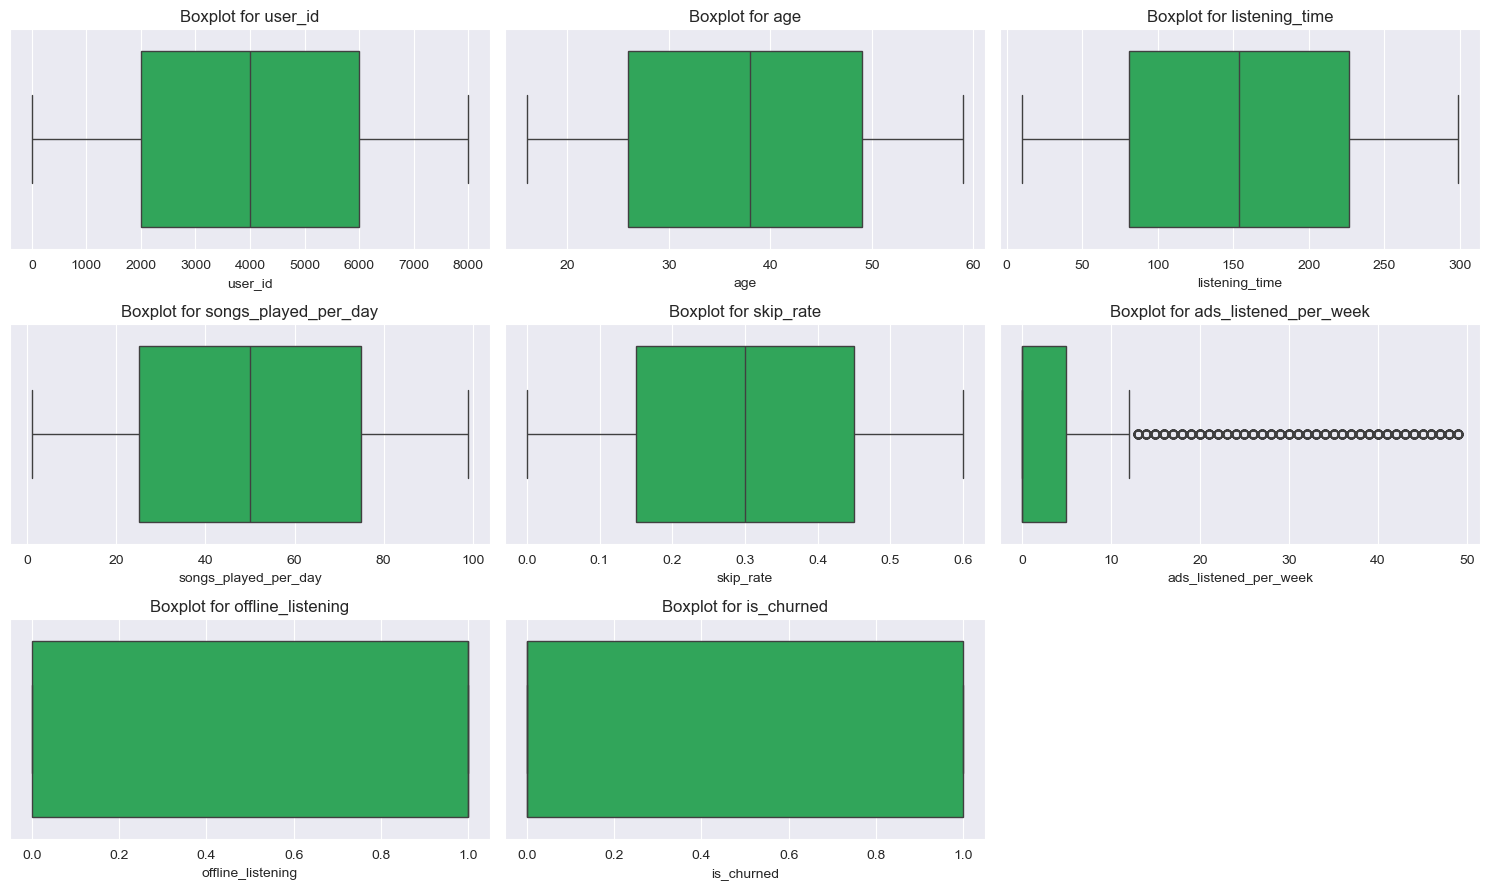

In [23]:
num_plots = len(numerical_cols)
ncols = 3
nrows = (num_plots + ncols - 1) // ncols


fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5 * ncols, 3 * nrows))

if nrows == 1 and ncols > 1:
    axes = axes.flatten()
elif nrows > 1:
    axes = axes.flatten()
elif nrows == 1 and ncols == 1:
    axes = [axes]

spotify_green = '#1DB954'

for i, col in enumerate(numerical_cols):
    sns.boxplot(x=df[col], ax=axes[i], color=spotify_green)

    axes[i].set_title(f'Boxplot for {col}', fontsize=12)
    axes[i].set_ylabel('')

for j in range(num_plots, nrows * ncols):
    fig.delaxes(axes[j])

plt.tight_layout()

plt.show()


# Outlier Handling

Lower bound: -7.5
Upper bound: 12.5


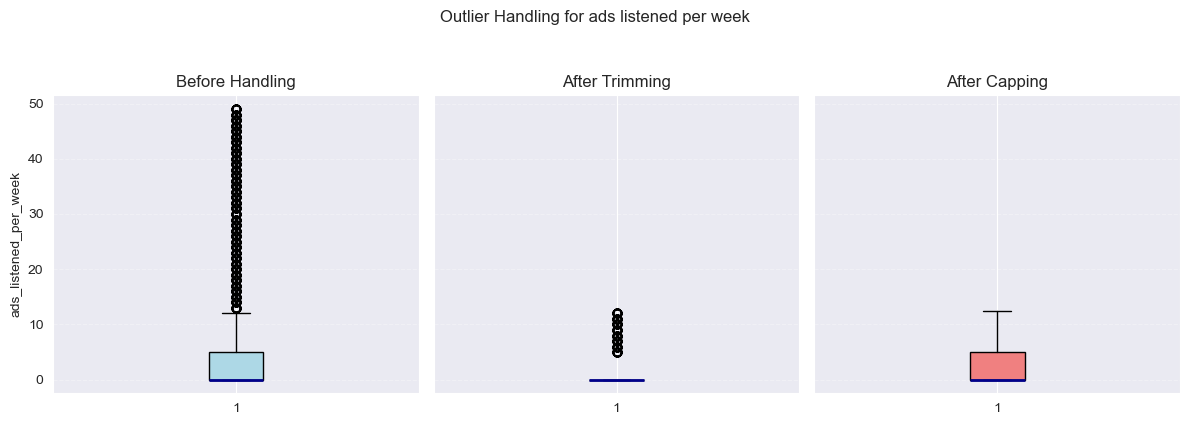

In [24]:
# Numeric column to process
num_col = "ads_listened_per_week"

# Compute IQR bounds
Q1 = df[num_col].quantile(0.25)
Q3 = df[num_col].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower bound:", lower)
print("Upper bound:", upper)

# Create trimmed dataset
df_trimmed = df[(df[num_col] >= lower) & (df[num_col] <= upper)]

# Create capped dataset
df_capped = df.copy()
df_capped[num_col] = df_capped[num_col].clip(lower=lower, upper=upper)

# Side-by-side boxplots
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
# Before handling
axes[0].boxplot(df[num_col].dropna(), vert=True, patch_artist=True,
                boxprops=dict(facecolor="lightblue", color="black"),
                medianprops=dict(color="darkblue", linewidth=2))
axes[0].set_title("Before Handling")
axes[0].set_ylabel(num_col)

# After trimming
axes[1].boxplot(df_trimmed[num_col].dropna(), vert=True, patch_artist=True,
                boxprops=dict(facecolor="lightgreen", color="black"),
                medianprops=dict(color="darkblue", linewidth=2))
axes[1].set_title("After Trimming")

# After capping
axes[2].boxplot(df_capped[num_col].dropna(), vert=True, patch_artist=True,
                boxprops=dict(facecolor="lightcoral", color="black"),
                medianprops=dict(color="darkblue", linewidth=2))
axes[2].set_title("After Capping")

for ax in axes:
    ax.grid(axis="y", alpha=0.3, linestyle="--")

fig.suptitle(f"Outlier Handling for ads listened per week", fontsize=12, y=1.05)
fig.tight_layout()
plt.show()

# Categorical features - pie charts

This cell identifies categorical columns and renders pie charts that show the composition of each categorical variable. Pie charts give a high-level sense of class balance but pair them with bar charts for more precise comparisons.

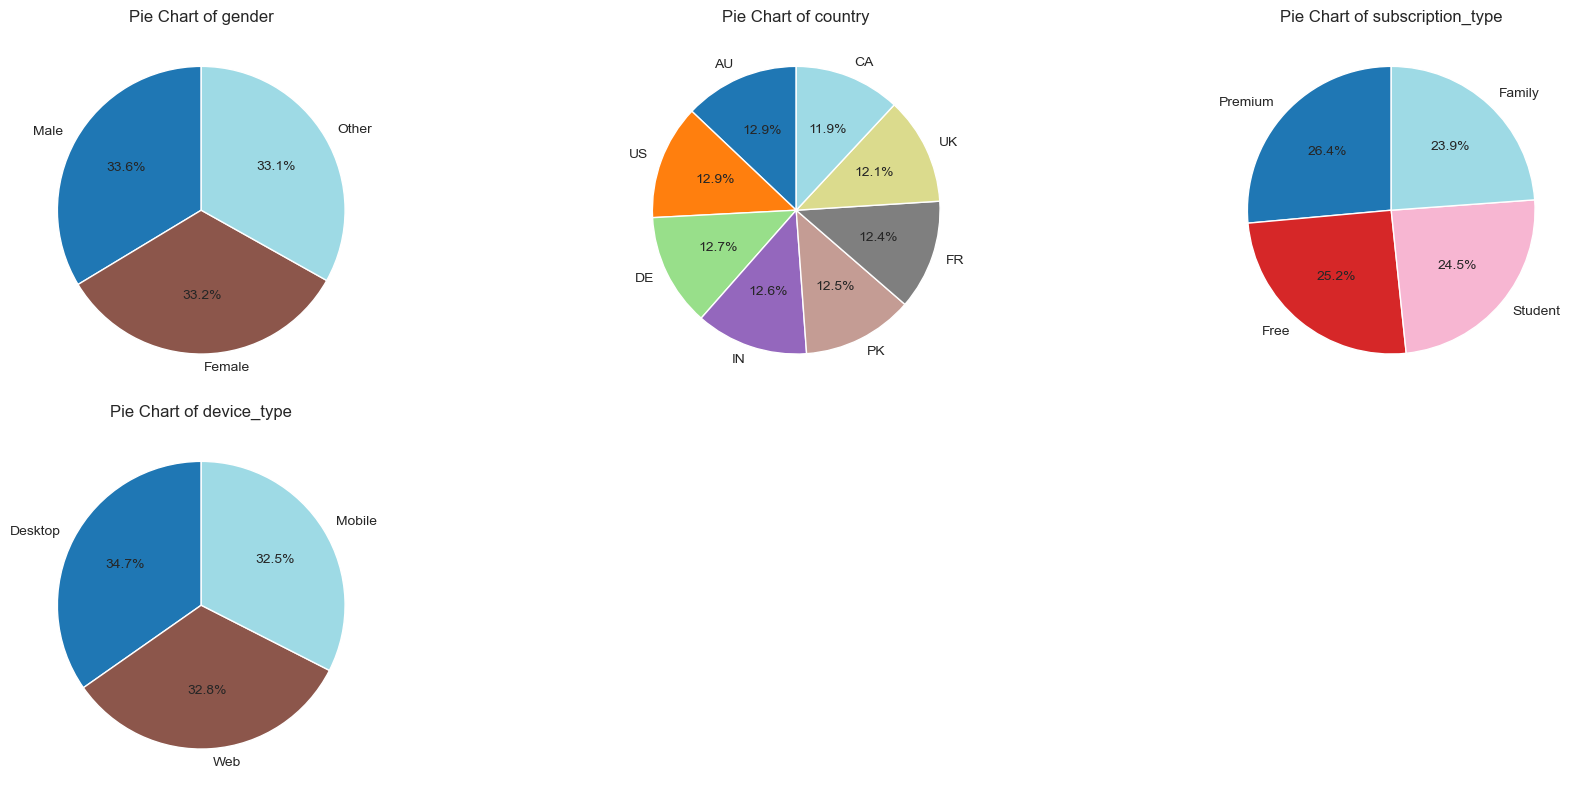

In [25]:
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

plt.figure(figsize=(18, 12))
for i, col in enumerate(categorical_cols, 1):
    plt.subplot(3, 3, i)
    df[col].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, cmap='tab20')
    plt.title(f'Pie Chart of {col}')
    plt.ylabel('')
plt.tight_layout()
plt.show()

# Top categories bar charts - categorical

For each categorical column, this plot shows the top values and their counts. Use it to find dominant categories and rare levels that you may collapse into "Other" during preprocessing.

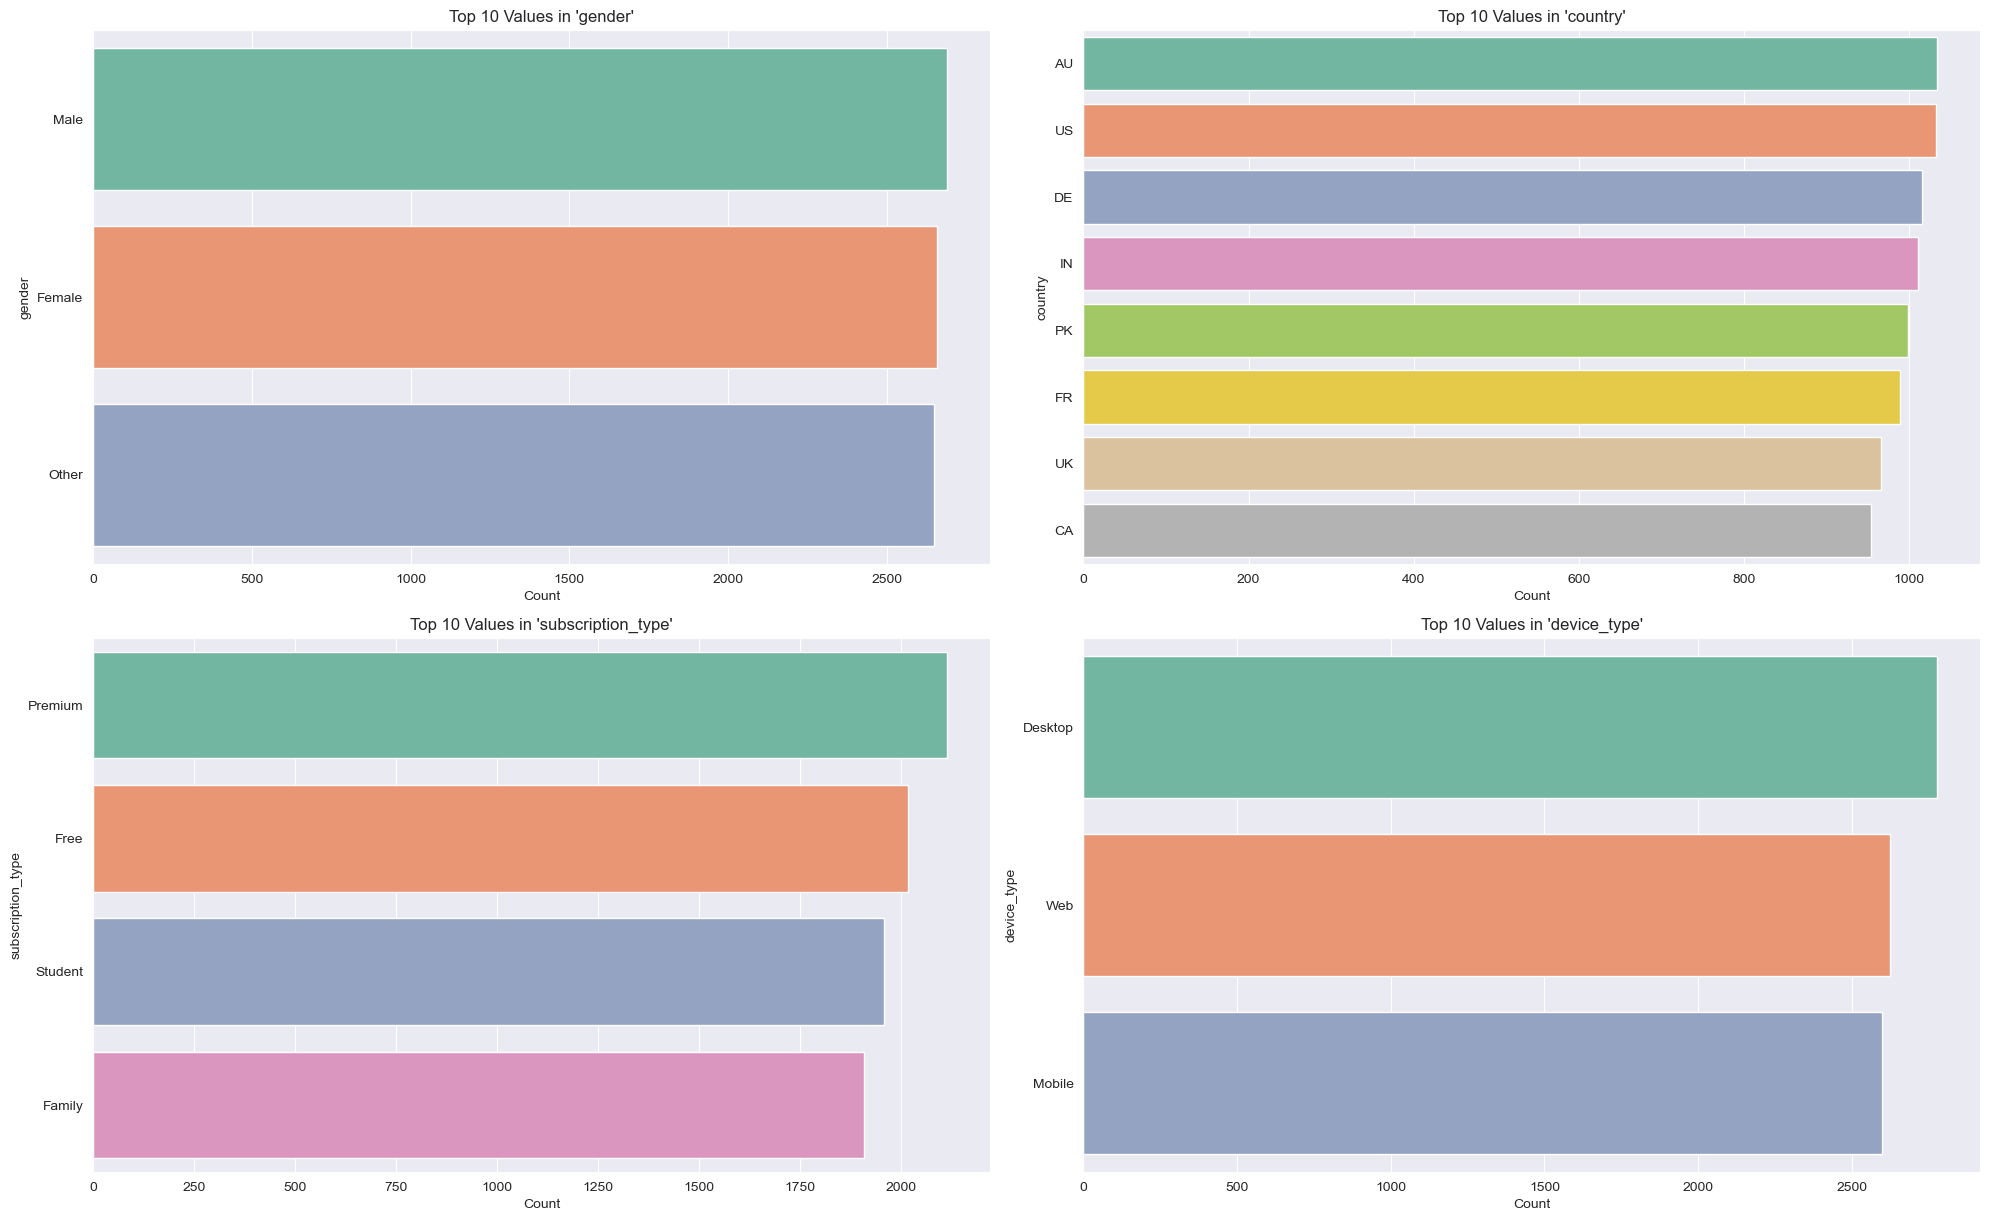

In [30]:
import warnings
warnings.filterwarnings('ignore')

plt.figure(figsize=(20, 18))
for i, col in enumerate(categorical_cols, 1):
    plt.subplot(3, 2, i)
    top_values = df[col].value_counts().nlargest(10)
    # Convert categories to string to avoid type issues
    sns.barplot(y=top_values.index.astype(str), x=top_values.values, palette='Set2')
    plt.title(f"Top 10 Values in '{col}'", fontsize=12)
    plt.xlabel("Count")
    plt.ylabel(col)
    plt.tight_layout()

plt.show()

## Target balance: churn vs non-churn

This plot visualizes how balanced the target `is_churned` is. Balanced classes are ideal for standard classifiers; if classes are strongly imbalanced you may need resampling or specialized metrics.

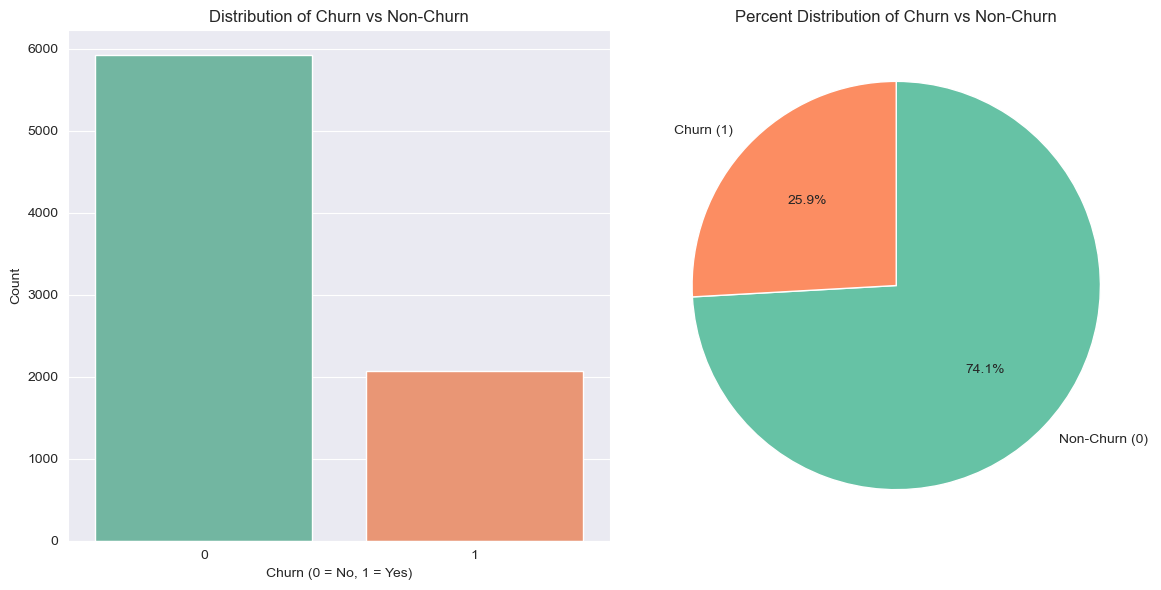

In [33]:
##Target Balance
churn_counts = df["is_churned"].value_counts()
labels = ["Non-Churn (0)", "Churn (1)"]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Countplot on the first subplot
sns.countplot(x="is_churned", data=df, palette="Set2", ax=axes[0])
axes[0].set_title("Distribution of Churn vs Non-Churn")
axes[0].set_xlabel("Churn (0 = No, 1 = Yes)")
axes[0].set_ylabel("Count")

# Pie chart on the second subplot
axes[1].pie(churn_counts, labels=labels, autopct='%1.1f%%', colors=sns.color_palette("Set2"),
            startangle=90, counterclock=False)
axes[1].set_title("Percent Distribution of Churn vs Non-Churn")

plt.tight_layout()
plt.show()

# Churn rate (percent)

This cell prints the percent distribution of `is_churned`. Keep this numeric summary alongside the plot for exact values.

In [17]:
#show %
churn_rate = df["is_churned"].value_counts(normalize=True) * 100
print("Churn Rate (%):")
print(churn_rate)

Churn Rate (%):
is_churned
0    74.1125
1    25.8875
Name: proportion, dtype: float64


# Visualising churn rate %

## Numeric features VS churn rate

Objective: For all numeric features, display side-by-side boxplots (or grouped boxplots) split by churn vs non-churn. This helps identify differences between the two groups that might be predictive.

Notes:
- We drop `is_churned` from the numeric set before plotting.
- Look for consistent shifts or variance differences between groups.

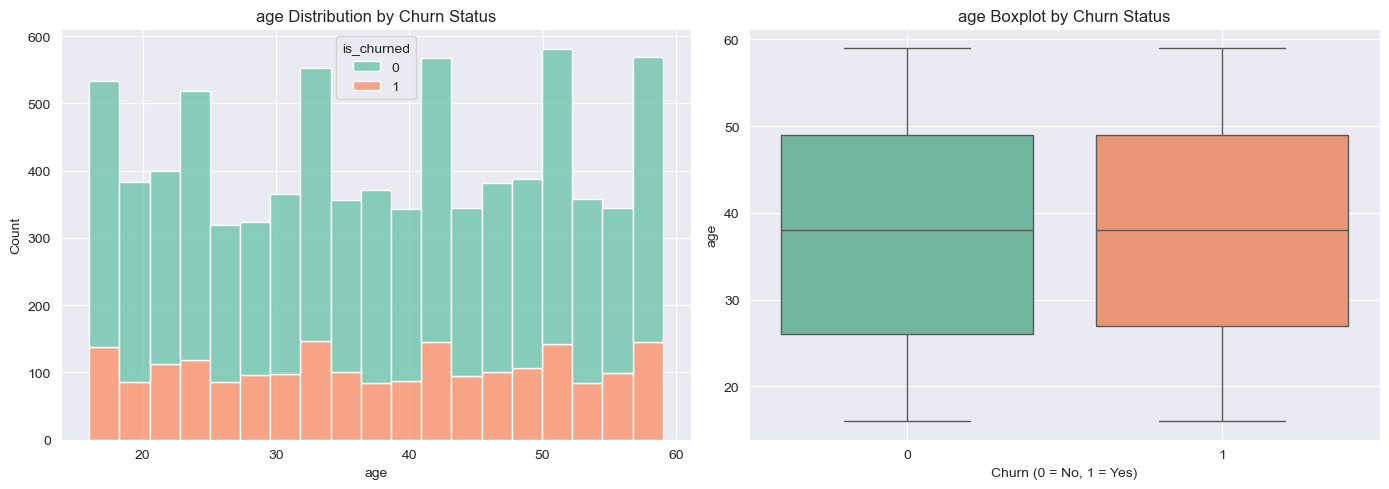

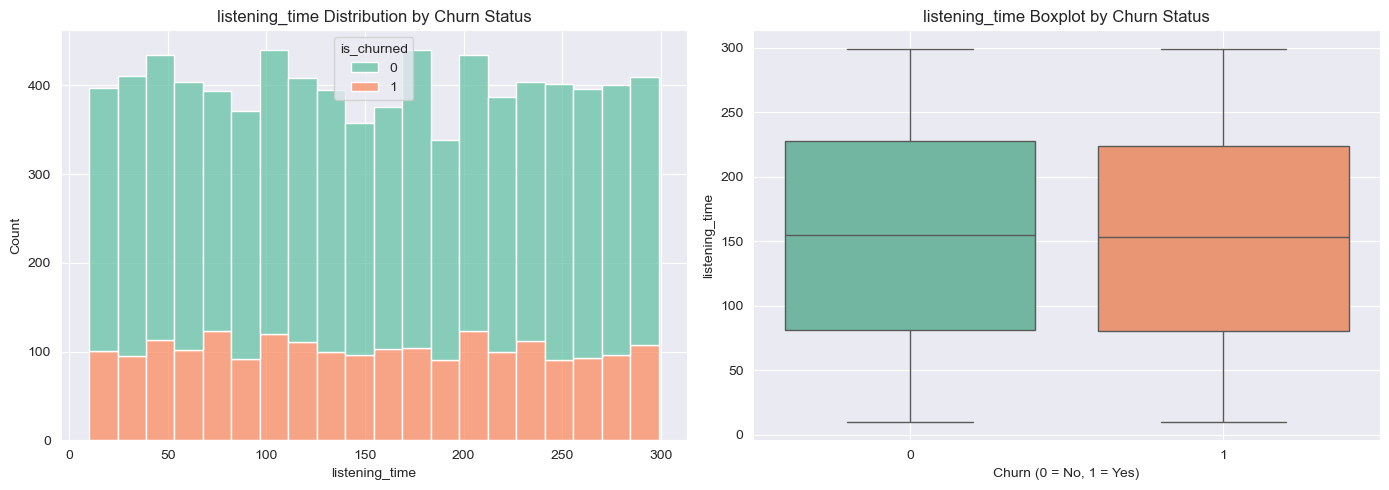

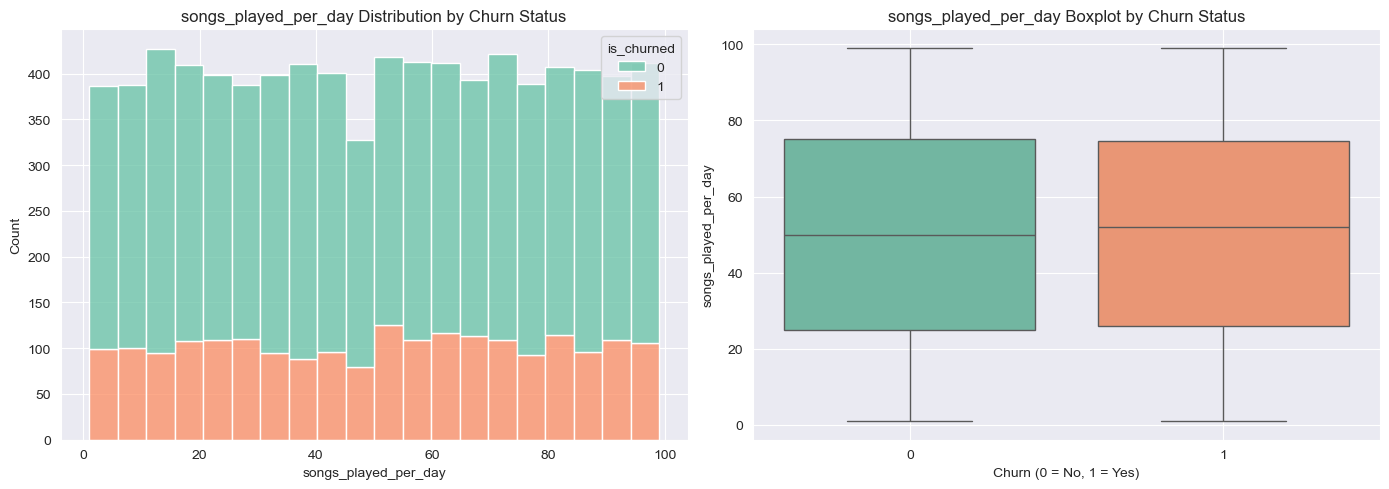

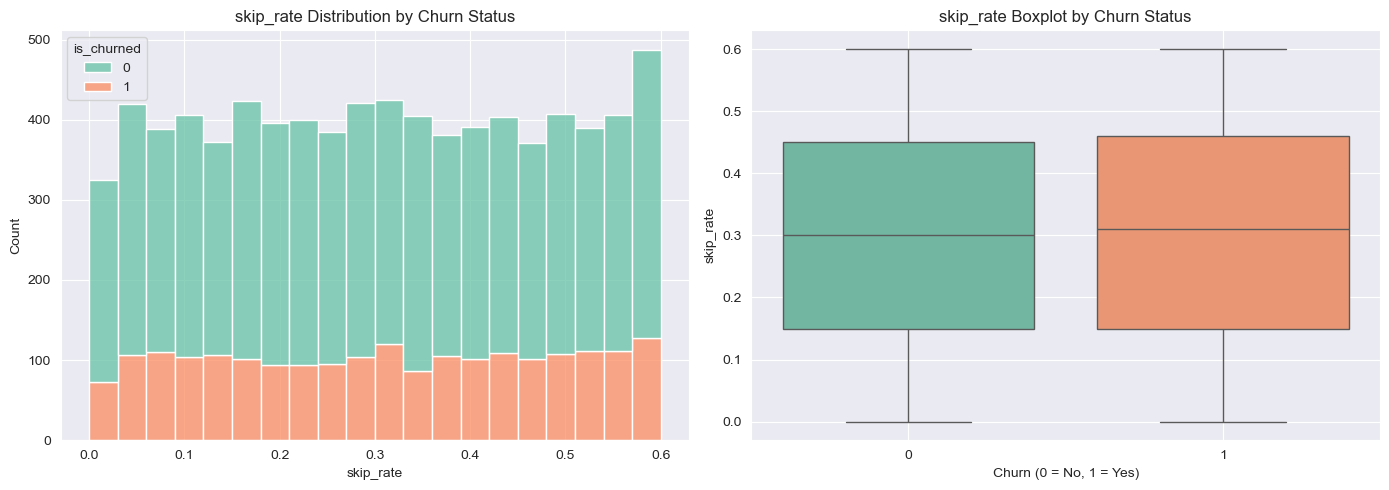

In [36]:
##🔎 Objective: Know the differences in distribution between churners and non-churners for each feature

numerical_cols = ['age', 'listening_time', 'songs_played_per_day', 'skip_rate']

for col in numerical_cols:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Histogram with hue for churn
    sns.histplot(data=df, x=col, hue='is_churned', multiple='stack', palette='Set2', ax=axes[0])
    axes[0].set_title(f'{col} Distribution by Churn Status')
    
    # Boxplot by churn
    sns.boxplot(data=df, x='is_churned', y=col, palette='Set2', ax=axes[1])
    axes[1].set_title(f'{col} Boxplot by Churn Status')
    axes[1].set_xlabel('Churn (0 = No, 1 = Yes)')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# Categorical features vs churn

For each categorical feature, this cell plots counts broken down by churn status (hue=`is_churned`). Use these plots to see if certain categories are over-represented in churners.

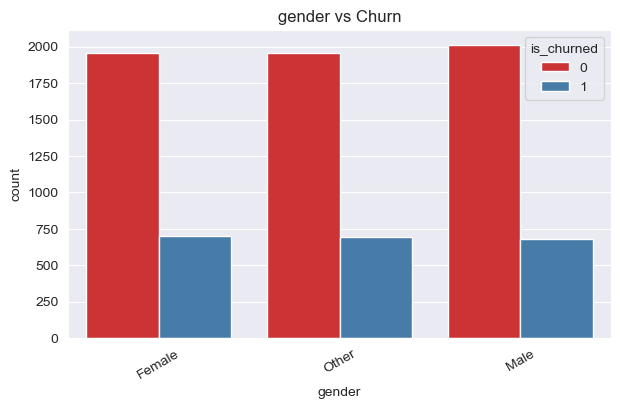

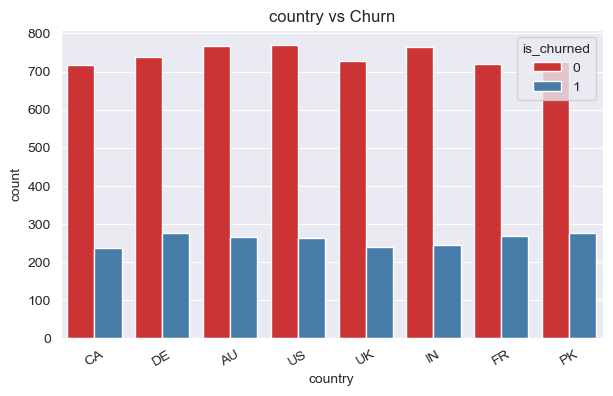

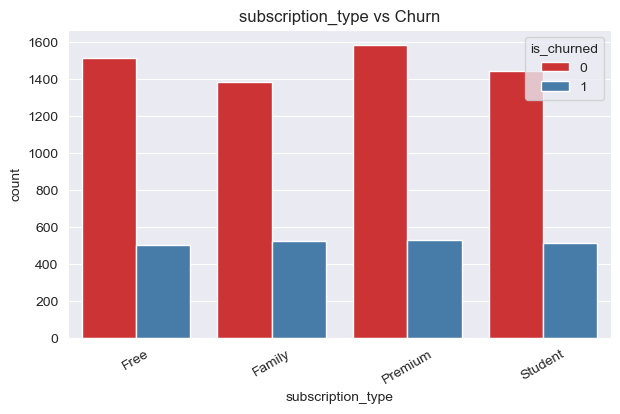

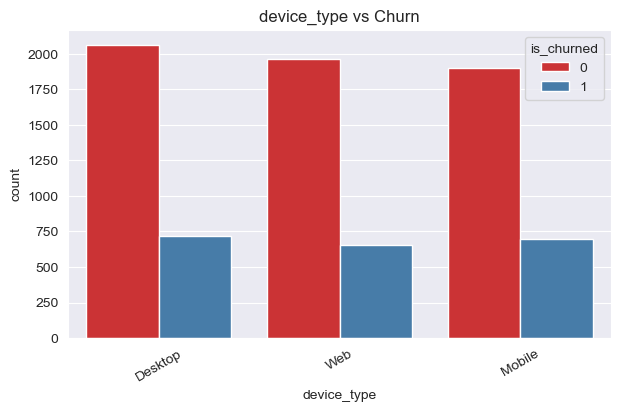

In [19]:
cat_features = df.select_dtypes(include=['object']).columns

for col in cat_features:
    plt.figure(figsize=(7,4))
    sns.countplot(x=col, hue="is_churned", data=df, palette="Set1")
    plt.title(f"{col} vs Churn")
    plt.xticks(rotation=30)
    plt.show()

## Statistical significance — categorical features (chi-square)

Goal: For each categorical feature, perform a chi-square test of independence between the categorical feature and `is_churned`. For each feature we print the p-value:
- p < 0.05 indicates statistical dependence (reject the null of independence).
- p >= 0.05 suggests no strong evidence that the categorical feature is associated with churn.

Notes/assumptions:
- Expected frequencies should generally be >= 5 for chi-square to be reliable. If many low counts occur, consider Fisher's exact test or combining rare levels.

In [20]:
##🔎 Objective: We know whether the differences we saw in the graphs are statistically significant or not.
for col in cat_features:
    contingency = pd.crosstab(df[col], df["is_churned"])
    chi2, p, dof, ex = chi2_contingency(contingency)
    print(f"{col}: p-value = {p}")

gender: p-value = 0.6004606500958493
country: p-value = 0.5448581401010985
subscription_type: p-value = 0.216110972429786
device_type: p-value = 0.30549848123857454


## Preliminary conclusion from categorical tests

Short textual conclusion summarizing the chi-square outputs. This cell notes that categorical variables did not show strong influences individually and suggests that the main signals may be in continuous/digital features (e.g., listening hours).

In [21]:
##Conclusion:
##Categorical factors (such as gender, country, device, subscription) do not have a strong influence on the customer’s decision whether to churn or not.

##The main impact may be on digital features (such as listening hours, number of songs, subscription duration...

## Pro analysis — numeric features (t-test)

For each numeric feature we perform an independent-samples t-test comparing the means between churned and non-churned users:
- The test prints p-values where p < 0.05 would indicate a significant mean difference.
- We use Welch’s t-test (equal_var=False) to avoid assuming equal variances.

Notes:
- T-test assumes approximate normality — if distributions are heavily skewed, consider non-parametric tests (Mann–Whitney U).

In [22]:
##Pro Analysis¶
num_features = df.select_dtypes(include=['int64','float64']).columns.drop("is_churned")

for col in num_features:
    churned = df[df["is_churned"]==1][col].dropna()
    non_churned = df[df["is_churned"]==0][col].dropna()
    t, p = ttest_ind(churned, non_churned, equal_var=False)
    print(f"{col}: p-value = {p}")

user_id: p-value = 0.14933857688676888
age: p-value = 0.7209312290600904
listening_time: p-value = 0.492440207283827
songs_played_per_day: p-value = 0.40397409604615586
skip_rate: p-value = 0.15051626043748986
ads_listened_per_week: p-value = 0.8392877293733654
offline_listening: p-value = 0.25022737880302104


# Short note on t-test results

A concise interpretation: if no single feature shows p < 0.05, it suggests that churn is likely driven by interactions of features rather than a single dominant variable. This is common in churn problems.

In [23]:
#📌 Basic conclusion:
#No feature alone was strongly influential (p-value < 0.05).

#This is normal in Customer Churn Analysis because the behavior depends on the Combination of Features, not a single feature.

# Multivariate analysis placeholder

Explore relationships between two or more variables to reveal dependencies and patterns not visible in univariate analysis.

### Methods include:

Numeric–Numeric relationships via scatter plots (e.g., age vs. listening time).

Correlation analysis and heatmaps to see strength and direction of relationships between multiple numeric variables.

Categorical–Numeric plots such as boxplots or group means to compare numeric distributions across categorical groups (e.g., churn rate by subscription type and age).

*These methods help identify which factors combine or correlate to influence churn, guiding feature engineering and modeling.*

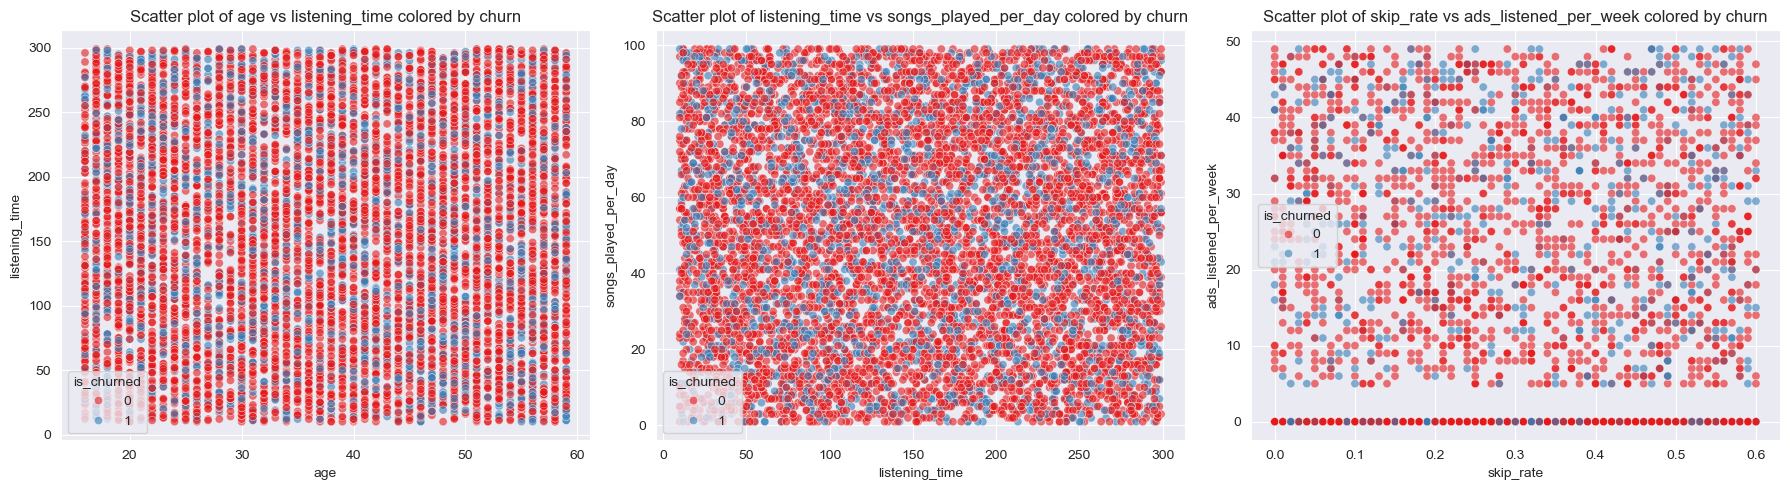

In [44]:
# 1. Numeric-Numeric: Scatter plots for pairs of numeric features
numeric_pairs = [('age', 'listening_time'), ('listening_time', 'songs_played_per_day'), ('skip_rate', 'ads_listened_per_week')]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))  # 1 row, 3 columns
for ax, (x_col, y_col) in zip(axes, numeric_pairs):
    sns.scatterplot(data=df, x=x_col, y=y_col, hue='is_churned', palette='Set1', alpha=0.6, ax=ax)
    ax.set_title(f'Scatter plot of {x_col} vs {y_col} colored by churn')
plt.tight_layout()
plt.show()


These scatter plots show no strong linear or simple numeric-numeric relationships purely by visual clustering.

Churn status overlaps broadly with numeric features, suggesting that churn prediction will likely depend on combinations of features or more advanced techniques than individual numeric pairs.

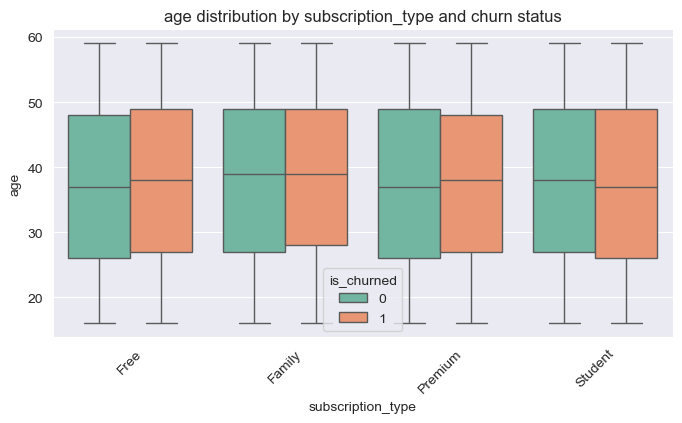

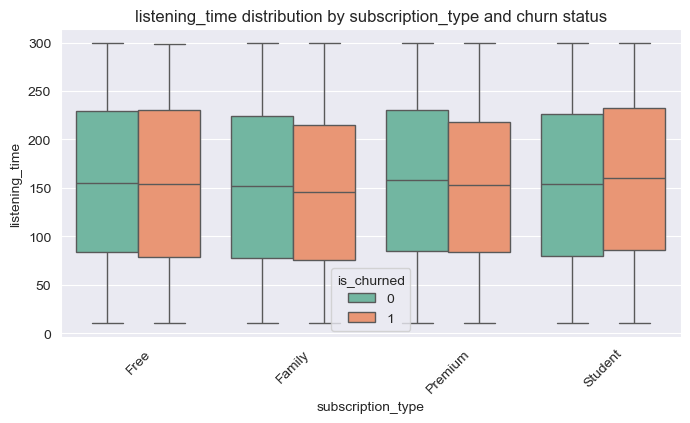

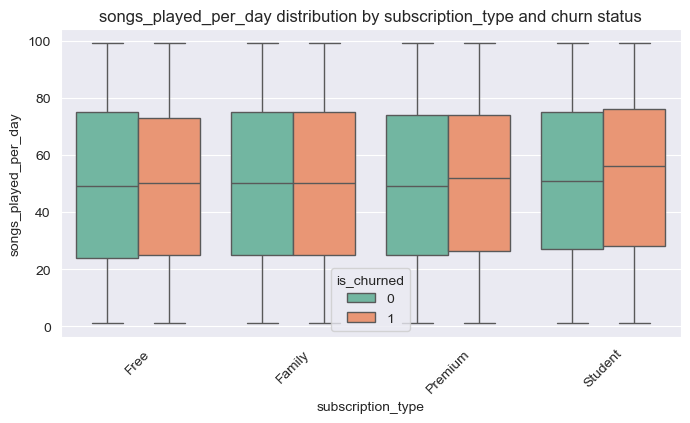

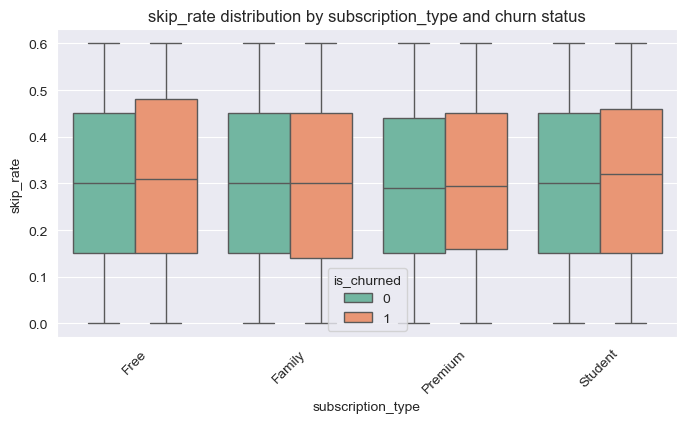

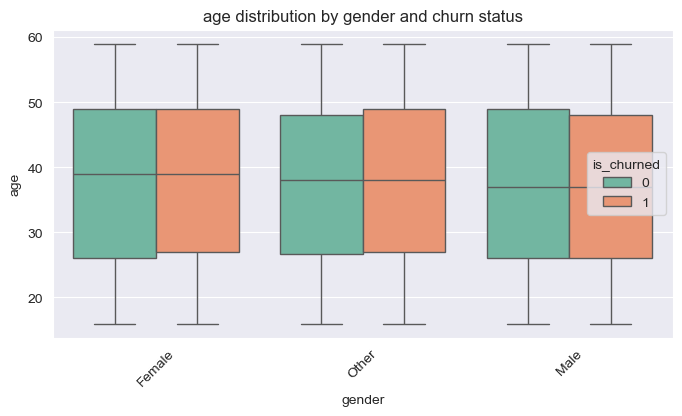

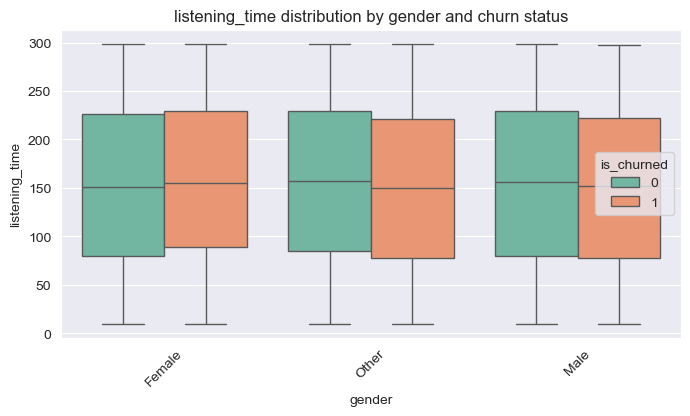

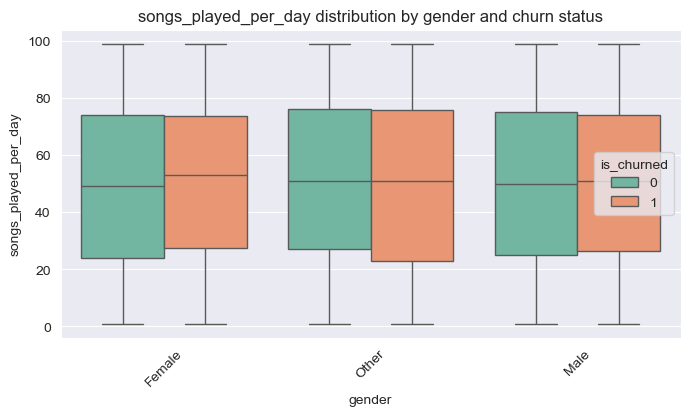

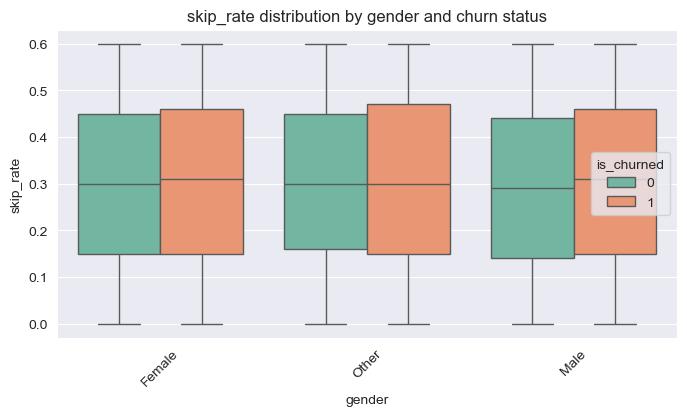

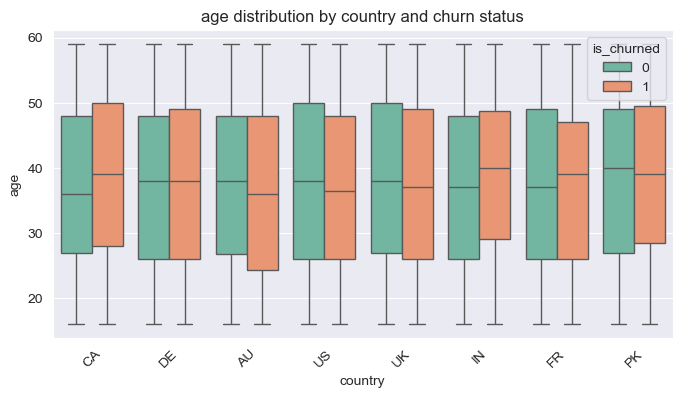

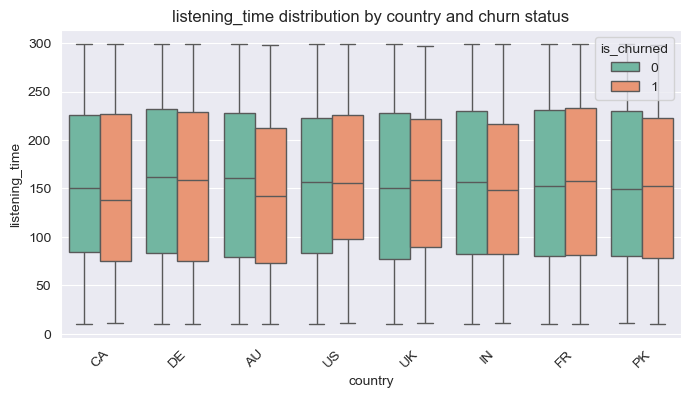

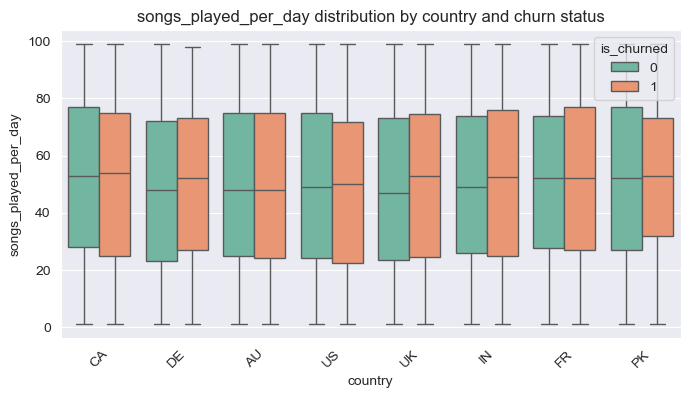

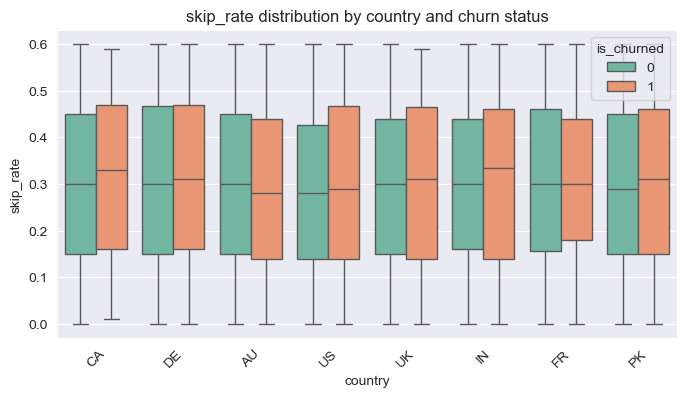

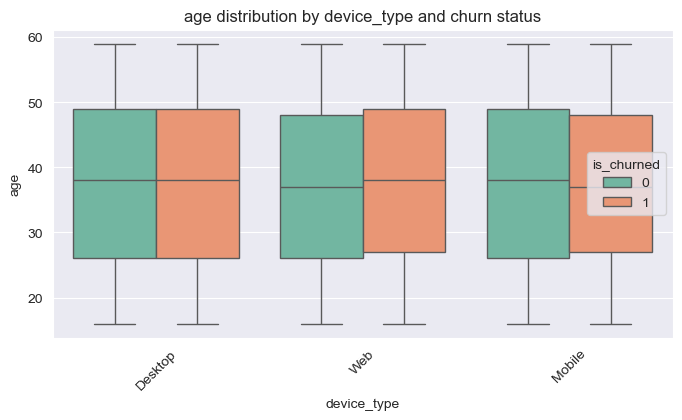

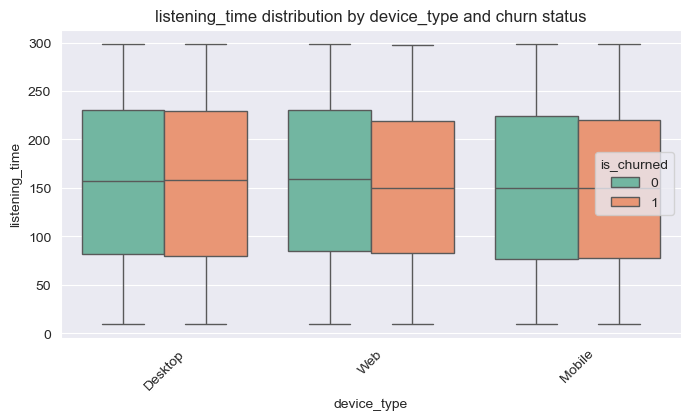

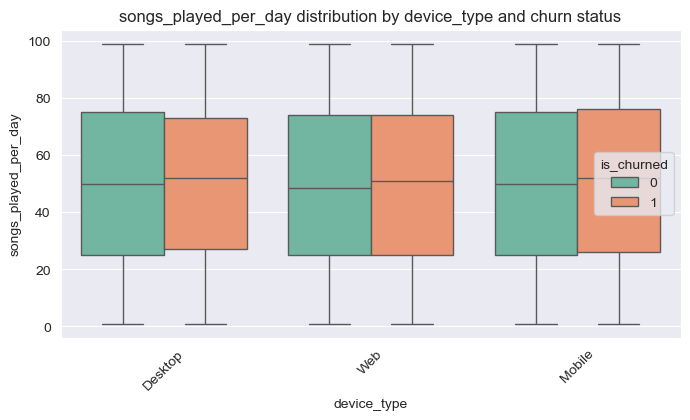

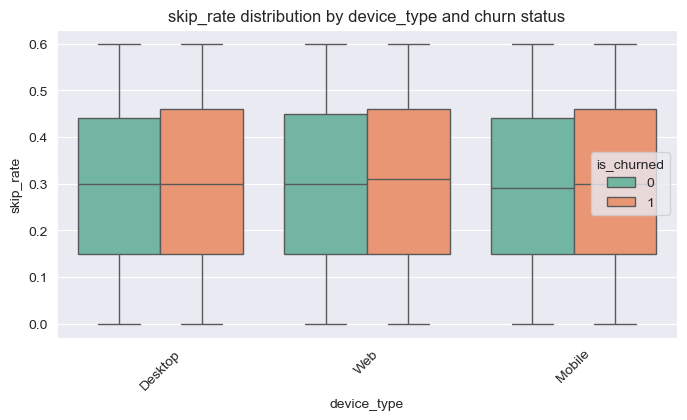

In [47]:
# 2. Categorical-Numeric: Boxplots for numeric features grouped by categorical attributes
categorical_cols = ['subscription_type', 'gender', 'country', 'device_type']
numeric_cols_to_plot = ['age', 'listening_time', 'songs_played_per_day', 'skip_rate']

for cat_col in categorical_cols:
    for num_col in numeric_cols_to_plot:
        plt.figure(figsize=(8, 4))
        sns.boxplot(data=df, x=cat_col, y=num_col, hue='is_churned', palette='Set2')
        plt.title(f'{num_col} distribution by {cat_col} and churn status')
        plt.xticks(rotation=45)
        plt.show()

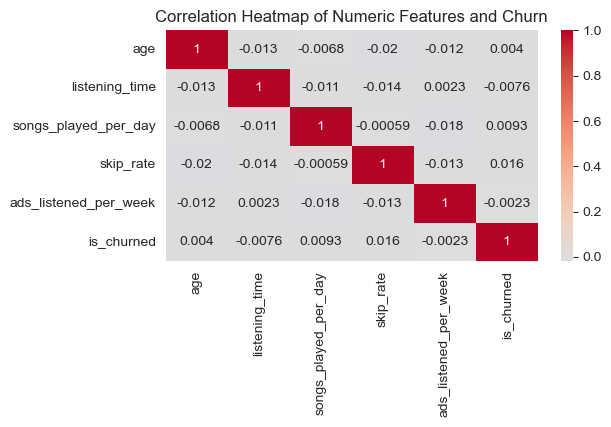

In [46]:
# 3. Correlation and Heatmap of numeric features
numeric_cols = ['age', 'listening_time', 'songs_played_per_day', 'skip_rate', 'ads_listened_per_week', 'is_churned']
corr_matrix = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(6, 3))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation Heatmap of Numeric Features and Churn')
plt.show()


The correlations between the features (age, listening_time, songs_played_per_day, skip_rate, ads_listened_per_week) and churn (is_churned) are all very close to zero, indicating almost no linear relationship between these numeric features and whether a person churns.

The highest absolute correlation with churn is 0.016 for skip_rate, which is still negligible.

Other features like age, listening_time, songs_played_per_day, and ads_listened_per_week have correlations close to zero with churn, indicating they do not linearly predict churn in this dataset.

There are also very weak correlations among the numeric features themselves, suggesting low redundancy and weak linear relationships between these quantitative variables.

Overall, this heatmap suggests that the numeric features provided have minimal linear predictive power for churn in this dataset. Nonlinear models or additional features might be needed to better predict churn. Also, other factors beyond these numeric ones could be more important in determining churn behavior.

# Temporal Analysis

## Feature importance — modeling setup

Short comment placeholder for the Random Forest modeling pipeline. This cell prepares `X` and `y` and encodes categorical variables with one-hot encoding. We also drop `user_id` (a unique identifier) and `is_churned` from features.

## Non Linear Model - Random Forest
Random Forests: Ensemble trees that improve accuracy and can capture complex, non-linear relationships between features. They are robust to overfitting and provide good interpretability compared to deep models.

## Train a Random Forest and plot top feature importances

This code trains a Random Forest classifier on the one-hot-encoded dataset and plots the top 10 feature importances. Notes:
- We use a simple 80/20 train-test split and a basic RandomForest (200 trees).
- Feature importances are useful for identifying signals but can be biased for high-cardinality categorical features; interpret with caution.

C:\Users\HP\AppData\Local\Temp\ipykernel_20304\3216246460.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[:10], y=importances.index[:10], palette="viridis")


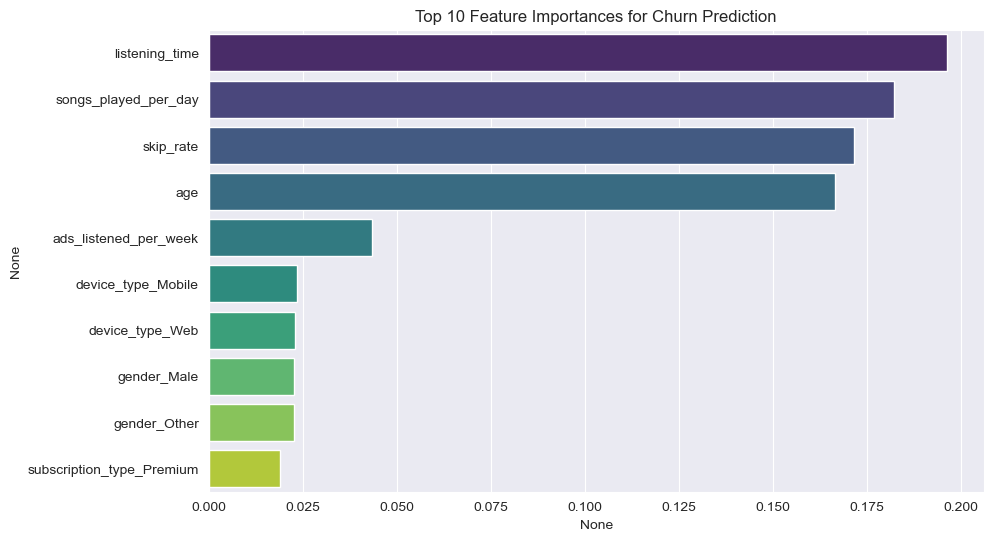

In [26]:
X = df.drop(columns=["is_churned", "user_id"])
y = df["is_churned"]

X = pd.get_dummies(X, drop_first=True)

# Train/Test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Random Forest
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

# Feature importance
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(x=importances[:10], y=importances.index[:10], palette="viridis")
plt.title("Top 10 Feature Importances for Churn Prediction")
plt.show()


From the above analysis, we can infere that listening time, songs played per day, skip rate and age play the most vital role in churn prediction.

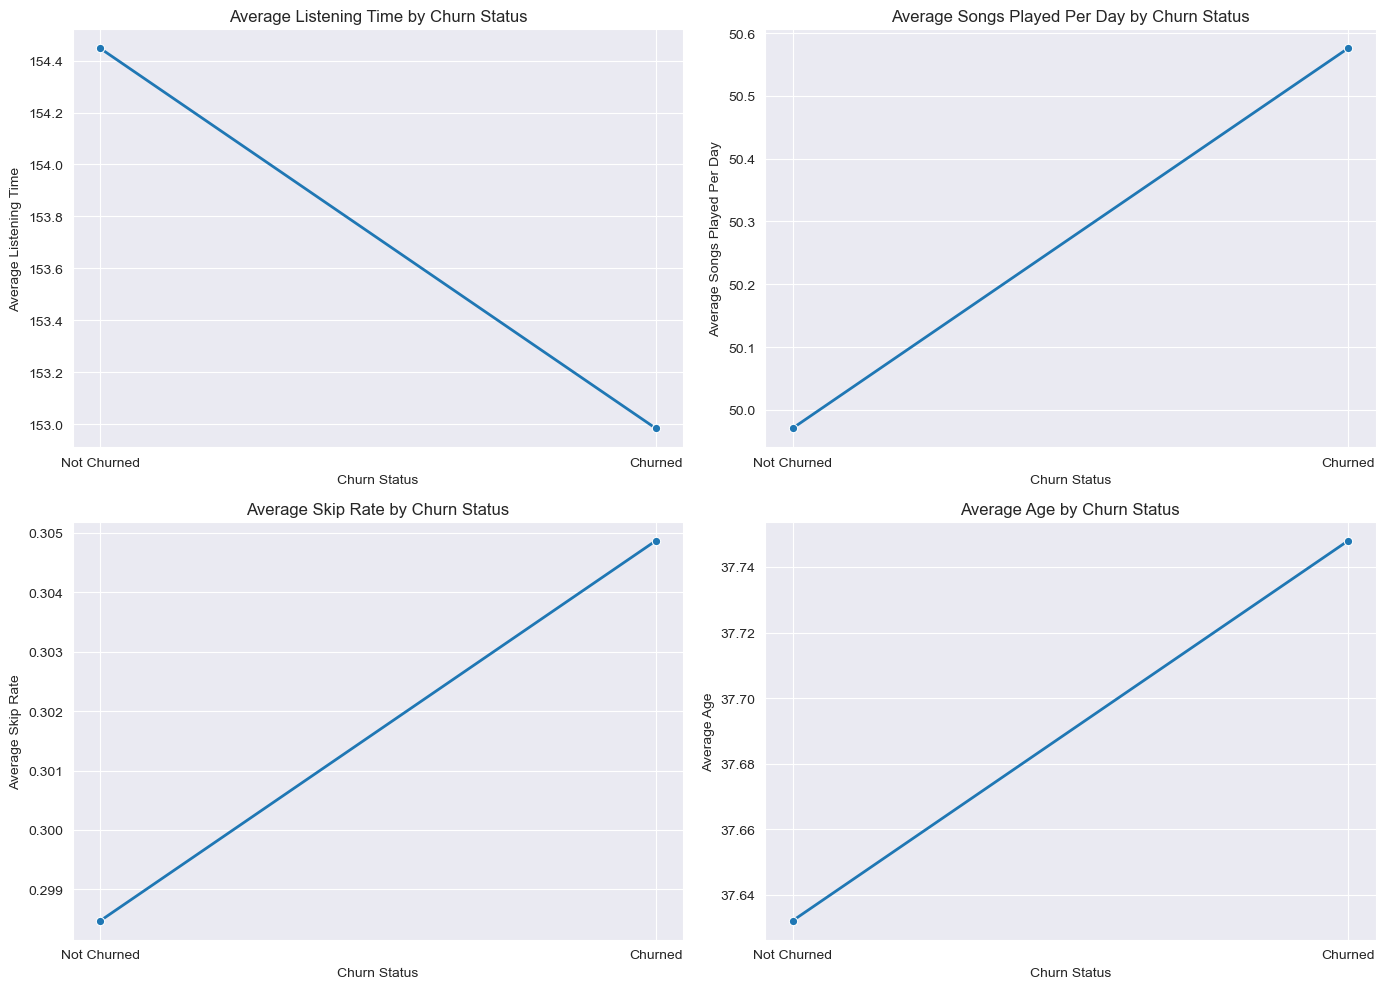

In [49]:
# Aggregate mean values by churn status
metrics = ['listening_time', 'songs_played_per_day', 'skip_rate', 'age']
agg_data = {metric: df.groupby('is_churned')[metric].mean() for metric in metrics}

fig, axes = plt.subplots(2, 2, figsize=(14,10))
axes = axes.flatten()

for i, metric in enumerate(metrics):
    data = agg_data[metric].reset_index()
    sns.lineplot(data=data, x='is_churned', y=metric, marker='o', ax=axes[i], linewidth=2)
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['Not Churned', 'Churned'])
    axes[i].set_title(f'Average {metric.replace("_", " ").title()} by Churn Status')
    axes[i].set_xlabel('Churn Status')
    axes[i].set_ylabel(f'Average {metric.replace("_", " ").title()}')

plt.tight_layout()
plt.show()


# Model evaluation — accuracy and classification report

This final cell:
- Predicts on the test set and prints accuracy and a detailed classification report (precision, recall, F1-score).
- Use these results as a baseline; further work might include tuning, cross-validation, class balancing, and additional models.

In [27]:
#Accuracy
y_pred = rf.predict(X_test)

print("✅ Model Evaluation")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

✅ Model Evaluation
Accuracy: 0.749375

Classification Report:
               precision    recall  f1-score   support

           0       0.75      0.99      0.86      1200
           1       0.47      0.02      0.04       400

    accuracy                           0.75      1600
   macro avg       0.61      0.51      0.45      1600
weighted avg       0.68      0.75      0.65      1600

